# EDA of parents in anatomy dataset

In [1]:
# ruff: noqa: T201, T203
from __future__ import annotations

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import logging

import pandas as pd
from dotenv import load_dotenv

from config.config import DATA_DIR
from src.evaluate import analyze_results, get_predictions_with_gt, plot_usage_histograms
from src.formatting import (
    format_oracle_pairs_filepath,
    format_run_path,
    format_storing_pathes_from_run_path,
)
from src.LLM_servers.openai import OpenAIServer
from src.onto_access import OntologyAccess
from src.onto_object import OntologyEntryAttr
from src.processing import parallel_samples_process
from src.prompts.system import BASELINE_INITIALIZATION_MESSAGE
from src.utils import read_oracle_pairs, save_run_results

logging.getLogger().setLevel(logging.WARNING)
load_dotenv()

%load_ext autoreload
%autoreload 2

In [2]:
llm_oracle = OpenAIServer()
llm_oracle.add_system_context(BASELINE_INITIALIZATION_MESSAGE)

In [3]:
DATASET_NAME = "anatomy"
SET_NAME = "human-mouse"
SOURCE_ONTOLOGY = "mouse"
TARGET_ONTOLOGY = "human"

DATASET_NAME = "bioml-2024"
SET_NAME = "omim-ordo"
SOURCE_ONTOLOGY = "omim"
TARGET_ONTOLOGY = "ordo"

src_onto_path = DATA_DIR / DATASET_NAME / SET_NAME / f"{SOURCE_ONTOLOGY}.owl"
tgt_onto_path = DATA_DIR / DATASET_NAME / SET_NAME / f"{TARGET_ONTOLOGY}.owl"

onto_src = OntologyAccess(src_onto_path, annotate_on_init=True)
onto_tgt = OntologyAccess(tgt_onto_path, annotate_on_init=True)

* Owlready2 * Creating new ontology ordo <data/bioml-2024/omim-ordo/ordo.owl#>.
* Owlready2 * ADD TRIPLE data/bioml-2024/omim-ordo/ordo.owl http://www.w3.org/1999/02/22-rdf-syntax-ns#type http://www.w3.org/2002/07/owl#Ontology
* Owlready2 *     ...loading ontology ordo from data/bioml-2024/omim-ordo/ordo.owl...


* Owlready2 * Reseting property ann.use_in_alignment: new triples are now available.


* Owlready2 *     ...41 properties found: BFO_0000050, Orphanet_317343, Orphanet_317344, Orphanet_317345, Orphanet_317346, Orphanet_317348, Orphanet_317349, Orphanet_327767, Orphanet_410295, Orphanet_410296, Orphanet_465410, Orphanet_C016, Orphanet_C017, Orphanet_C020, Orphanet_C022, Orphanet_C025, Orphanet_C026, Orphanet_C027, Orphanet_C024, Orphanet_C028, Orphanet_C029, Orphanet_C030, Orphanet_C032, Orphanet_C040, label, versionInfo, use_in_alignment, alternative_term, ECO_0000205, ECO_0000218, creator, created, license, modified, definition, definition_citation, reason_for_obsolescence, symbol, notation, permits, requires


### Utils Functions

In [ ]:
def select_best_direct_entity_names(
    src_entity: OntologyEntryAttr, tgt_entity: OntologyEntryAttr
) -> list[OntologyEntryAttr, OntologyEntryAttr]:
    """If there are multiple direct parents, select one and find child element for it."""
    src_parents = next(iter(src_entity.get_direct_parents()))
    tgt_parents = next(iter(tgt_entity.get_direct_parents()))
    return [x.get_preffered_names() if x else None for x in [src_parents, tgt_parents, src_entity, tgt_entity]]


def format_hierarchy(hierarchy_dict: dict[int, set[OntologyEntryAttr]], no_level: bool = False) -> str:
    formatted = []
    for level, parents in sorted(hierarchy_dict.items()):
        parent_name = next(iter(next(iter(parents)).get_all_entity_names()))
        if no_level:
            formatted.append(parent_name)
        else:
            formatted.append(f"\tLevel {level}: {parent_name}")

    if no_level:
        return formatted
    return "\n".join(formatted)

### Prompt templates

In [ ]:
def prompt_direct_entity(src_entity: OntologyEntryAttr, tgt_entity: OntologyEntryAttr) -> str:
    """Regular prompt that uses natural language and is more intuitive."""
    src_parent, tgt_parent, src_entity_names, tgt_entity_names = select_best_direct_entity_names(src_entity, tgt_entity)
    return f"""We have two entities from different biomedical ontologies.
The first one is "{src_entity_names}", which falls under the category "{src_parent}".
The second one is "{tgt_entity_names}", which falls under the category "{tgt_parent}".

Do they mean the same thing? Respond with "True" or "False".
"""


def prompt_direct_entity_ontological(src_entity: OntologyEntryAttr, tgt_entity: OntologyEntryAttr) -> str:
    """Ontological prompt that uses ontology-focused language."""
    src_parent, tgt_parent, src_entity_names, tgt_entity_names = select_best_direct_entity_names(src_entity, tgt_entity)
    return f"""Analyze the following entities, each originating from a distinct biomedical ontology.
Your task is to assess whether they represent the **same ontological concept**, considering both their semantic meaning and hierarchical position.

1. Source entity: "{src_entity_names}"
\t- Direct ontological parent: "{src_parent}"

2. Target entity: "{tgt_entity_names}"
\t- Direct ontological parent: "{tgt_parent}"

Are these entities **ontologically equivalent** within their respective ontologies? Respond with "True" or "False".
"""  # noqa: E501


def prompt_sequential_hierarchy(src_entity: OntologyEntryAttr, tgt_entity: OntologyEntryAttr) -> str:
    """Regular prompt that uses natural language and is more intuitive."""
    src_hierarchy = format_hierarchy(src_entity.get_parents_by_levels(max_level=3), True)
    tgt_hierarchy = format_hierarchy(tgt_entity.get_parents_by_levels(max_level=3), True)

    return "\n".join(
        [
            "We have two entities from different biomedical ontologies.",
            (
                f'The first one is "{src_entity.get_preffered_names()}"'
                + (f', which belongs to the broader category "{src_hierarchy[0]}"' if len(src_hierarchy) >= 1 else "")
                + (f', under the even broader category "{src_hierarchy[1]}"' if len(src_hierarchy) >= 2 else "")
            ),
            (
                f'The second one is "{tgt_entity.get_preffered_names()}"'
                + (f', which belongs to the broader category "{tgt_hierarchy[0]}"' if len(tgt_hierarchy) >= 1 else "")
                + (f', under the even broader category "{tgt_hierarchy[1]}"' if len(tgt_hierarchy) >= 2 else "")
            ),
            'Do they mean the same thing? Respond with "True" or "False".',
        ]
    )


def prompt_sequential_hierarchy_ontological(src_entity: OntologyEntryAttr, tgt_entity: OntologyEntryAttr) -> str:
    """Ontological prompt that uses ontology-focused language, and takes hierarchical relationships into account."""
    src_hierarchy = format_hierarchy(src_entity.get_parents_by_levels(max_level=3))
    tgt_hierarchy = format_hierarchy(tgt_entity.get_parents_by_levels(max_level=3))

    return f"""The following entities come from distinct biomedical ontologies.
Each is represented by its **ontological lineage**, capturing its hierarchical placement from the most general to the most specific level.

1. Source entity ontological lineage:
{src_hierarchy}

2. Target entity ontological lineage:
{tgt_hierarchy}

Based on their **ontological positioning, hierarchical relationships, and semantic alignment**, do these entities represent the **same ontological concept**? Respond with "True" or "False".
"""  # noqa: E501


In [6]:
EXP_NAMES_TO_PROMPT_FUNCTIONS = {
    prompt_function.__name__.replace("prompt_", ""): prompt_function
    for prompt_function in [
        prompt_direct_entity,
        prompt_direct_entity_ontological,
        prompt_sequential_hierarchy,
        prompt_sequential_hierarchy_ontological,
    ]
}

src_entity, tgt_entity = read_oracle_pairs(format_oracle_pairs_filepath(DATASET_NAME, SET_NAME))[0]
src_entity, tgt_entity = OntologyEntryAttr(src_entity, onto_src), OntologyEntryAttr(tgt_entity, onto_tgt)

print(src_entity)
print(tgt_entity)

for name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():
    print(f"Prompt function: {name}")
    print(prompt_function(src_entity, tgt_entity))
    print("=" * 50)

{'class': phenotypicSeries.PS277400, 'uri': 'http://www.omim.org/phenotypicSeries/PS277400', 'preffered_names': {'Methylmalonic aciduria and homocystinuria'}, 'synonyms': {'PS277400'}, 'all_names': {'Methylmalonic aciduria and homocystinuria'}, 'parents': {owl.Thing}, 'children': {entry.309541, entry.277410, entry.277400, entry.277380, entry.614857}}
{'class': ORDO.Orphanet_293355, 'uri': 'http://www.orpha.net/ORDO/Orphanet_293355', 'preffered_names': {'Methylmalonic acidemia without homocystinuria'}, 'synonyms': {'Methylmalonic aciduria without homocystinuria'}, 'all_names': {'Methylmalonic acidemia without homocystinuria', 'Methylmalonic aciduria without homocystinuria'}, 'parents': {ORDO.Orphanet_377794, ORDO.Orphanet_C001, owl.Thing, ORDO.Orphanet_79163, ORDO.Orphanet_289899, ORDO.Orphanet_68367, ORDO.Orphanet_98053, ORDO.Orphanet_79062}, 'children': set()}
Prompt function: direct_entity
We have two entities from different biomedical ontologies.
The first one is "{'Methylmalonic ac

### Run experiments

Processing Lines prompt_direct_entity: 100%|██████████| 1464/1464 [17:10<00:00,  1.42it/s]


Mean input tockens: 156.4
Mean output tockens: 6.0
Total input tockens: 228995
Total output tockens: 8784


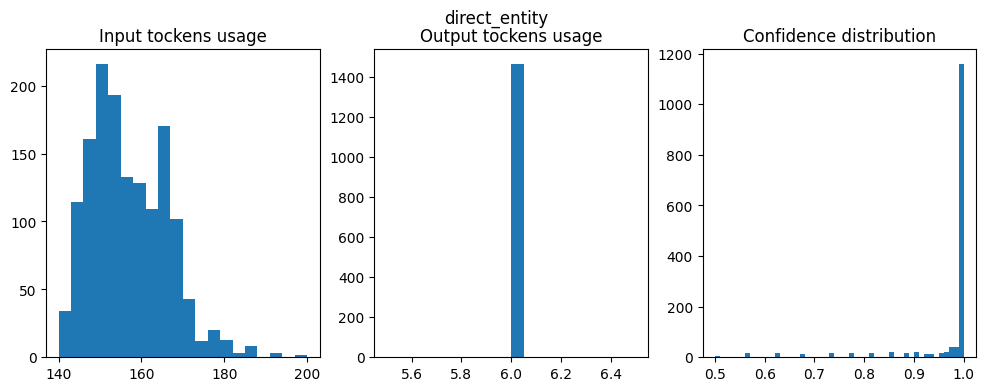

Accuracy: 0.643
Precision: 0.879
Recall: 0.630
F1 Score: 0.734


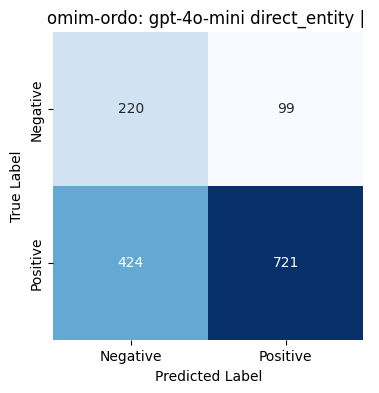

Processing Lines prompt_direct_entity_ontological: 100%|██████████| 1464/1464 [16:46<00:00,  1.45it/s] 


Mean input tockens: 196.4
Mean output tockens: 6.0
Total input tockens: 287555
Total output tockens: 8784


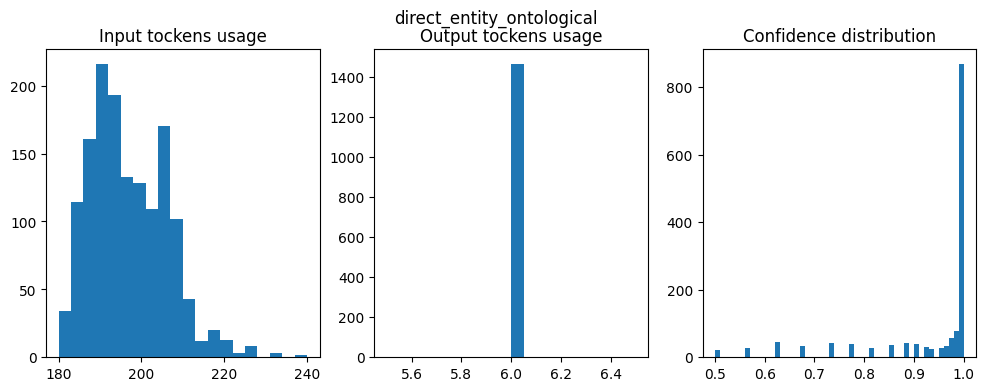

Accuracy: 0.516
Precision: 0.881
Recall: 0.440
F1 Score: 0.587


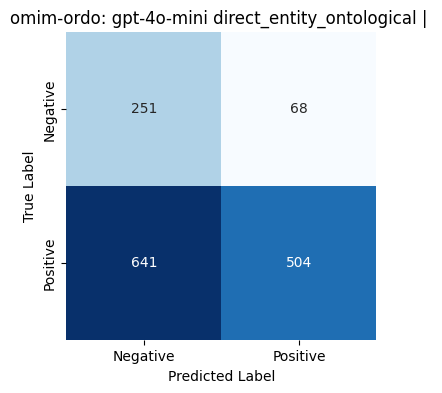

Processing Lines prompt_sequential_hierarchy: 100%|██████████| 1464/1464 [22:02<00:00,  1.11it/s] 


Mean input tockens: 182.1
Mean output tockens: 6.0
Total input tockens: 266593
Total output tockens: 8784


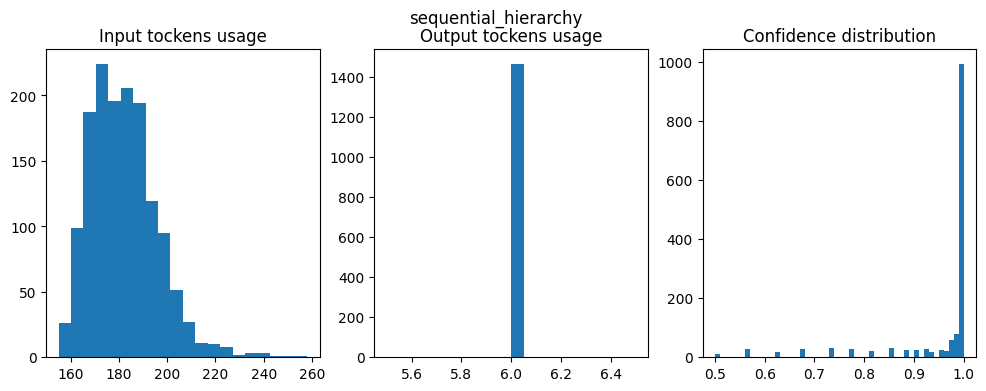

Accuracy: 0.536
Precision: 0.883
Recall: 0.469
F1 Score: 0.613


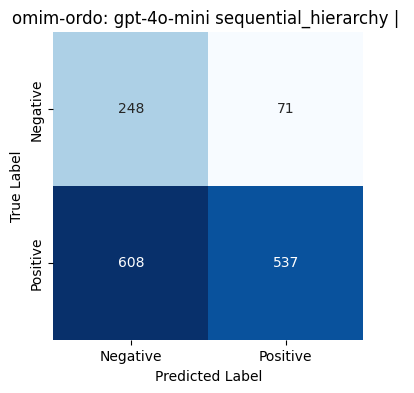

Processing Lines prompt_sequential_hierarchy_ontological: 100%|██████████| 1464/1464 [22:30<00:00,  1.08it/s] 


Mean input tockens: 219.9
Mean output tockens: 6.0
Total input tockens: 321922
Total output tockens: 8784


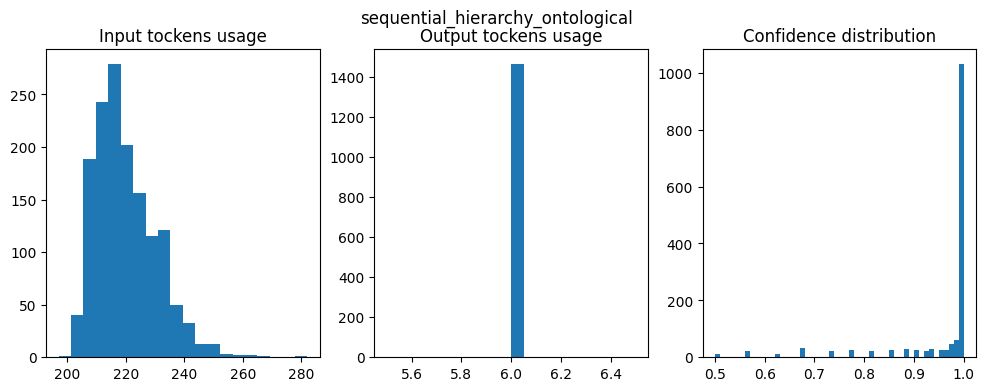

Accuracy: 0.354
Precision: 0.824
Recall: 0.221
F1 Score: 0.348


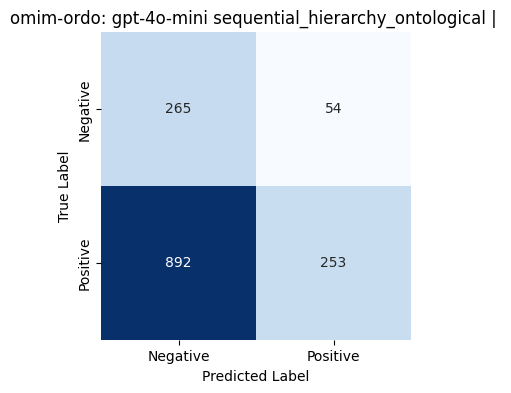

In [7]:
MAX_WORKERS = 50
MODEL = "gpt-4o-mini"

oracle_candidate_pairs_path = format_oracle_pairs_filepath(DATASET_NAME, SET_NAME)

oracle_candidate_pairs = read_oracle_pairs(oracle_candidate_pairs_path)[:]

run_path = format_run_path()

for current_exp_name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():
    results, tokens_usage, confidences = parallel_samples_process(
        oracle_candidate_pairs, llm_oracle, onto_src, onto_tgt, MODEL, MAX_WORKERS, prompt_function
    )
    prediction_path, stats_path, diagram_path = format_storing_pathes_from_run_path(
        run_path, SET_NAME, MODEL, current_exp_name
    )
    save_run_results(results, prediction_path, columns=["Source", "Target", "Prediction", "Confidence"])

    plot_usage_histograms(tokens_usage, confidences, do_plot=True, do_print=True, suptitle=current_exp_name)

    predictions = get_predictions_with_gt(run_path, DATASET_NAME, SET_NAME, MODEL, current_exp_name)
    analyze_results(
        predictions,
        print_results=True,
        plot_confusion_matrix=True,
        subtitle=f"{SET_NAME}: {MODEL} {current_exp_name} | ",
        cm_save_path=diagram_path,
        stats_path=stats_path,
    )
    print("\n")


## Analysis

In [8]:
results_data = []

# run_path = Path("runs/2025-03-02_10-11-18")

for exp_name in EXP_NAMES_TO_PROMPT_FUNCTIONS:
    _, stats_path, _ = format_storing_pathes_from_run_path(run_path, SET_NAME, MODEL, exp_name)
    stats = pd.read_csv(stats_path, index_col=0).T
    results_data.append(
        {
            "Experiment": exp_name,
            **{key: stats[key].to_numpy()[0] for key in stats.columns},
        }
    )

results_df = pd.DataFrame(results_data).round(4)
results_df.to_csv(run_path / "results.csv", index=False)
results_df

,Experiment,Accuracy,Precision,Recall,F1 Score
0,direct_entity,0.6428,0.8793,0.6297,0.7338
1,direct_entity_ontological,0.5157,0.8811,0.4402,0.5871
2,sequential_hierarchy,0.5362,0.8832,0.4690,0.6127
3,sequential_hierarchy_ontological,0.3538,0.8241,0.2210,0.3485
